## 1. Setup and configuration

In [2]:
import os, sys, json, random, time, math, shutil, subprocess, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2.functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

IN_COLAB = "google.colab" in sys.modules

# ---- where persistent files live (checkpoints, cache, metadata) ----
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path(os.environ.get("WORK_DIR", "/content/drive/MyDrive/shoplifting_project"))
    DATA_DIR = Path("/content/data")            # raw videos: local disk (fast), re-downloaded only if needed
else:
    WORK_DIR = Path(os.environ.get("WORK_DIR", "./shoplifting_project"))
    DATA_DIR = WORK_DIR / "data"

CACHE_DIR = WORK_DIR / "cache"
CKPT_DIR  = WORK_DIR / "checkpoints_resnet18"   # new folder: old from-scratch checkpoints are NOT reused
for d in (WORK_DIR, DATA_DIR, CACHE_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    drive_file_id = "1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-",
    T             = 16,      # frames sampled per video
    cache_size    = 144,     # frames are stored at cache_size x cache_size
    img_size      = 128,     # network input size (random crop for training)
    batch_size    = int(os.environ.get("BATCH_SIZE", 16)),
    epochs        = int(os.environ.get("EPOCHS", 30)),
    backbone_lr   = 1e-4,     # pretrained ResNet18: small LR
    head_lr       = 1e-3,     # GRU + attention + classifier (random init)
    weight_decay  = 1e-2,
    patience      = 8,      # early stopping on val F1
    seed          = 42,
    val_frac      = 0.15,
    test_frac     = 0.15,
    num_workers   = int(os.environ.get("NUM_WORKERS", min(4, os.cpu_count() or 1))),
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| work dir:", WORK_DIR.resolve())

device: cuda | work dir: /kaggle/working/shoplifting_project


## 2. Download the dataset with `wget`
The download is skipped when the frame cache is already complete or the videos are already on disk.
The Drive file must be shared as *Anyone with the link*.

In [3]:
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".mpg", ".mpeg", ".wmv", ".flv", ".webm"}
META_CSV = WORK_DIR / "metadata.csv"
ZIP_PATH = DATA_DIR / "Shop_DataSet.zip"

def list_videos(root):
    return sorted(p for p in Path(root).rglob("*") if p.suffix.lower() in VIDEO_EXTS)

def cache_complete():
    if not META_CSV.exists():
        return False
    meta = pd.read_csv(META_CSV)
    return all((CACHE_DIR / f"{i}.npy").exists() for i in meta["id"])

def wget_drive(file_id, out_path):
    url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t"
    subprocess.run(["wget", "--no-check-certificate", "-q", "--show-progress", "-O", str(out_path), url], check=False)
    if not zipfile.is_zipfile(out_path):                      # fallback if wget got an HTML page
        print("wget did not return a zip, falling back to gdown ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(id=file_id, output=str(out_path), quiet=False)
    assert zipfile.is_zipfile(out_path), "Download failed. Check that the Drive link is public."

if cache_complete():
    print("Frame cache already complete -> download skipped.")
elif list_videos(DATA_DIR):
    print(f"{len(list_videos(DATA_DIR))} videos already on disk -> download skipped.")
else:
    if not ZIP_PATH.exists():
        wget_drive(CFG["drive_file_id"], ZIP_PATH)
    print("Extracting ...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    ZIP_PATH.unlink(missing_ok=True)                           # save disk space
    print("Videos found:", len(list_videos(DATA_DIR)))


     0K .......... .......... .......... .......... ..........  0% 73.1M 23s
    50K .......... .......... .......... .......... ..........  0% 52.6M 28s
   100K .......... .......... .......... .......... ..........  0% 31.4M 36s
   150K .......... .......... .......... .......... ..........  0% 57.7M 35s
   200K .......... .......... .......... .......... ..........  0%  101M 31s
   250K .......... .......... .......... .......... ..........  0% 51.4M 31s
   300K .......... .......... .......... .......... ..........  0% 61.0M 31s
   350K .......... .......... .......... .......... ..........  0%  102M 29s
   400K .......... .......... .......... .......... ..........  0% 62.3M 29s
   450K .......... .......... .......... .......... ..........  0% 35.0M 31s
   500K .......... .......... .......... .......... ..........  0% 85.2M 30s
   550K .......... .......... .......... .......... ..........  0% 68.5M 29s
   600K .......... .......... .......... .......... ..........  0% 40.1M 30

Extracting ...
Videos found: 855


## 3. Explore the dataset
Labels are inferred from the folder names (`non shop lifters` / `normal` -> 0, `shop lifters` / `shoplift*` / `theft` -> 1). Metadata is cached in `metadata.csv`.

probing videos:   0%|          | 0/855 [00:00<?, ?it/s]

Metadata built.

Clips per class:
 label
normal         531
shoplifting    324

Duration (s) / frames per class:
label                 0       1
duration count   531.00  324.00
         mean     13.93   12.22
         std       5.37    3.35
         min       3.00    4.00
         25%      11.00   10.00
         50%      14.00   12.00
         75%      16.00   15.00
         max      74.00   23.03
n_frames count   531.00  324.00
         mean    347.78  304.60
         std     134.20   83.47
         min      75.00  100.00
         25%     275.00  248.00
         50%     348.00  300.00
         75%     400.00  372.00
         max    1850.00  570.00

Frame resolutions:
 width  height
704    576       855


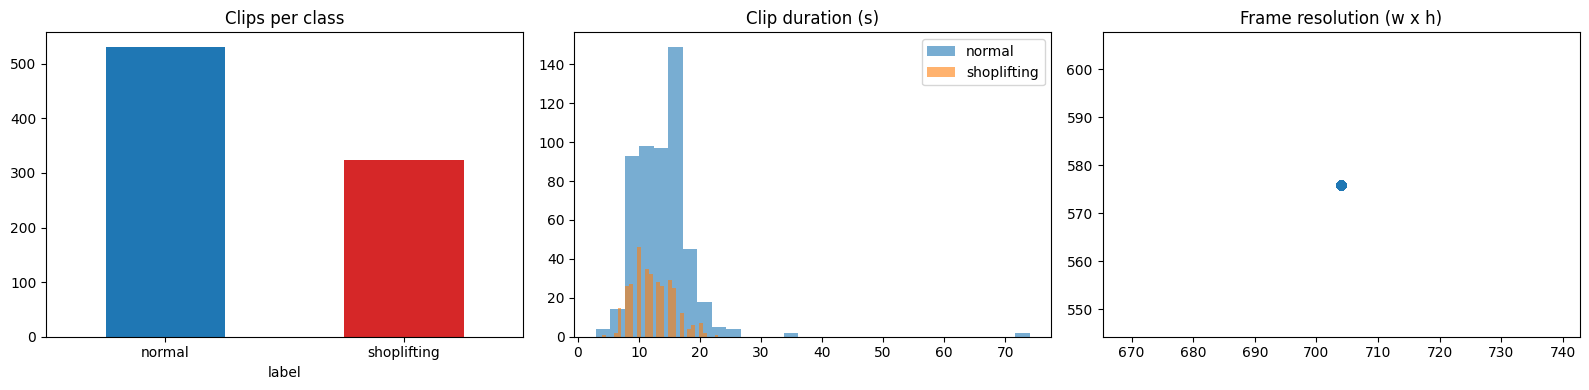

In [4]:
def infer_label(path):
    """Label from the parent folder name. Negative keywords are checked first ('non shop lifters' contains 'shop lift')."""
    folder = Path(path).parent.name.lower().replace("_", " ").replace("-", " ")
    if any(k in folder for k in ("non shop", "nonshop", "non-shop", "normal", "not shop")):
        return 0
    if any(k in folder for k in ("shop lift", "shoplift", "theft", "steal")):
        return 1
    return None

def probe_video(path):
    cap = cv2.VideoCapture(str(path))
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

def build_metadata():
    videos = list_videos(DATA_DIR)
    assert videos, f"No videos found under {DATA_DIR}"
    rows = []
    for p in tqdm(videos, desc="probing videos"):
        label = infer_label(p)
        if label is None:
            continue
        n, fps, w, h = probe_video(p)
        if n <= 0 or w <= 0:
            print("skipping unreadable video:", p); continue
        rows.append(dict(path=str(p), label=label, n_frames=n, fps=fps, duration=n / fps, width=w, height=h))
    if not rows:
        tree = sorted({str(p.parent.relative_to(DATA_DIR)) for p in videos})[:20]
        raise RuntimeError(f"Could not infer labels from folders. Folders seen: {tree}")
    meta = pd.DataFrame(rows).reset_index(names="id")
    meta.to_csv(META_CSV, index=False)
    return meta

if META_CSV.exists() and cache_complete():
    meta = pd.read_csv(META_CSV)
    print("Loaded cached metadata.")
else:
    meta = build_metadata()
    print("Metadata built.")

CLASS_NAMES = ["normal", "shoplifting"]
print("\nClips per class:\n", meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().to_string())
print("\nDuration (s) / frames per class:")
print(meta.groupby("label")[["duration", "n_frames"]].describe().T.round(2).to_string())
print("\nFrame resolutions:\n", meta.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0)
ax[0].set_title("Clips per class")
for lbl, name in enumerate(CLASS_NAMES):
    ax[1].hist(meta.loc[meta.label == lbl, "duration"], bins=30, alpha=.6, label=name)
ax[1].set_title("Clip duration (s)"); ax[1].legend()
ax[2].scatter(meta["width"], meta["height"], alpha=.4); ax[2].set_title("Frame resolution (w x h)")
plt.tight_layout(); plt.show()

## 4. Uniform frame sampling
For a video with `N` frames and target `T`, the skip interval is `skip = N / T`. The video is split into `T` equal segments and the **centre frame of each segment** is taken:

`idx_i = floor(skip * i + skip / 2)`, for `i = 0 ... T-1`

The samples therefore span the whole clip evenly (gaps differ by at most 1 frame). If `N < T`, frames are repeated evenly.

N=     1 skip=    0.06 -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
N=     5 skip=    0.31 -> [0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4]
N=    15 skip=    0.94 -> [0, 1, 2, 3, 4, 5, 6, 7, 7, 8, 9, 10, 11, 12, 13, 14]
N=    16 skip=    1.00 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
N=    17 skip=    1.06 -> [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16]
N=    31 skip=    1.94 -> [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]
N=   100 skip=    6.25 -> [3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
N=   257 skip=   16.06 -> [8, 24, 40, 56, 72, 88, 104, 120, 136, 152, 168, 184, 200, 216, 232, 248]
N=  1000 skip=   62.50 -> [31, 93, 156, 218, 281, 343, 406, 468, 531, 593, 656, 718, 781, 843, 906, 968]
N= 12345 skip=  771.56 -> [385, 1157, 1928, 2700, 3472, 4243, 5015, 5786, 6558, 7329, 8101, 8872, 9644, 10416, 11187, 11959]

Frame sampling verified for all lengths.


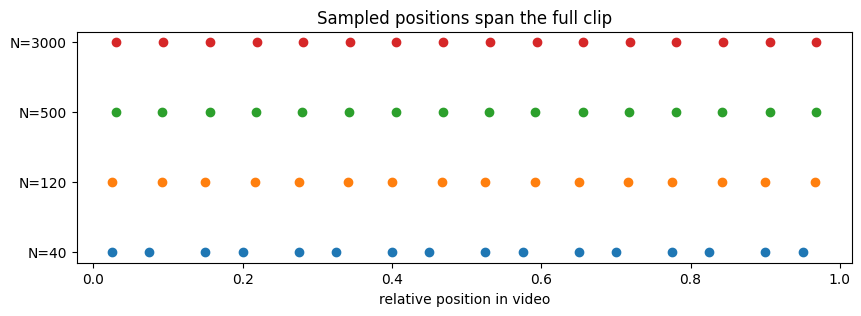

In [5]:
def uniform_sample_indices(n_frames: int, T: int) -> np.ndarray:
    """Return T frame indices spread uniformly over [0, n_frames)."""
    if n_frames <= 0:
        raise ValueError("n_frames must be positive")
    if n_frames < T:                                           # short video: repeat frames evenly
        idx = np.linspace(0, n_frames - 1, T).round()
    else:
        skip = n_frames / T                                    # uniform skip interval
        idx = np.floor(skip * np.arange(T) + skip / 2)
    return np.clip(idx.astype(int), 0, n_frames - 1)

# ---- verification on clips of very different lengths ----
test_lengths = [1, 5, 15, 16, 17, 31, 100, 257, 1000, 12345]
T = CFG["T"]
for n in test_lengths:
    idx = uniform_sample_indices(n, T)
    assert len(idx) == T and idx.min() >= 0 and idx.max() < n and np.all(np.diff(idx) >= 0)
    if n >= T:
        skip = n / T
        gaps = np.diff(idx)
        assert gaps.max() - gaps.min() <= 1, "gaps must be uniform within 1 frame"
        assert idx[0] < skip and idx[-1] >= n - skip, "samples must span the whole clip"
    print(f"N={n:>6} skip={n / T:8.2f} -> {idx.tolist()}")
print("\nFrame sampling verified for all lengths.")

fig, ax = plt.subplots(figsize=(10, 3))
for k, n in enumerate([40, 120, 500, 3000]):
    ax.scatter(uniform_sample_indices(n, T) / n, [k] * T)
ax.set_yticks(range(4)); ax.set_yticklabels(["N=40", "N=120", "N=500", "N=3000"])
ax.set_xlabel("relative position in video"); ax.set_title("Sampled positions span the full clip"); plt.show()

## 5. Read sampled frames and cache them
Each video is decoded **once**: `T` uniformly sampled frames are resized to `cache_size x cache_size` and stored as a uint8 `.npy`. Training then never touches the video decoder again, which makes epochs very fast and the stage resumable (existing files are skipped).

In [6]:
def count_frames_by_grab(path):
    cap = cv2.VideoCapture(str(path)); n = 0
    while cap.grab():
        n += 1
    cap.release()
    return n

def read_sampled_frames(path, T, size, n_hint=None):
    """Decode a video once and return a uint8 array (T, size, size, 3) in RGB."""
    n = n_hint or count_frames_by_grab(path)
    for attempt in range(2):
        idx = uniform_sample_indices(n, T)
        wanted = {}
        for pos, i in enumerate(idx):
            wanted.setdefault(int(i), []).append(pos)
        frames = [None] * T
        cap = cv2.VideoCapture(str(path)); i = 0; last_needed = max(wanted)
        while i <= last_needed:
            ok, frame = cap.read()
            if not ok:
                break
            if i in wanted:
                rgb = cv2.cvtColor(cv2.resize(frame, (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
                for pos in wanted[i]:
                    frames[pos] = rgb
            i += 1
        cap.release()
        if all(f is not None for f in frames):
            return np.stack(frames)
        n = count_frames_by_grab(path)                         # metadata frame count was wrong -> recount, retry
    last = next((f for f in reversed(frames) if f is not None), None)
    if last is None:
        raise RuntimeError(f"Cannot decode {path}")
    return np.stack([f if f is not None else last for f in frames])

def cache_one(row):
    out = CACHE_DIR / f"{row.id}.npy"
    if out.exists():
        return None
    try:
        arr = read_sampled_frames(row.path, CFG["T"], CFG["cache_size"], int(row.n_frames))
        np.save(out, arr)
        return None
    except Exception as e:
        return (row.id, row.path, str(e))

if cache_complete():
    print("Frame cache already complete -> skipped.")
else:
    todo = [r for r in meta.itertuples() if not (CACHE_DIR / f"{r.id}.npy").exists()]
    print(f"Caching {len(todo)} / {len(meta)} videos ...")
    with ThreadPoolExecutor(max_workers=CFG["num_workers"] or 1) as ex:
        errors = [e for e in tqdm(ex.map(cache_one, todo), total=len(todo)) if e]
    if errors:
        print(f"{len(errors)} videos failed and are dropped:", errors[:3])
        meta = meta[~meta["id"].isin([e[0] for e in errors])].reset_index(drop=True)
        meta.to_csv(META_CSV, index=False)
    print("Done.")

Caching 855 / 855 videos ...


  0%|          | 0/855 [00:00<?, ?it/s]

Done.


## 6. Stratified train / val / test split (saved to `splits.csv`)

In [17]:

# WEEK 6 — ROBUST GROUP-AWARE DATA SPLITTING
# Includes duplicate hashing, group creation and leakage verification.

import hashlib
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

# 1. Verify required columns
required = {"id", "path", "label"}

missing = required - set(meta.columns)

if missing:
    raise ValueError(f"Missing metadata columns: {missing}")

# 2. Generate exact content hashes if not already available
def calculate_sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

if "video_hash" not in meta.columns:
    print("Generating video hashes...")

    meta["video_hash"] = [
        calculate_sha256(p)
        for p in tqdm(meta["path"], desc="SHA256")
    ]

# 3. Create grouping variable
meta["group_id"] = meta["video_hash"]

# 4. Detect conflicting labels
conflicts = (
    meta.groupby("group_id")["label"]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

if len(conflicts):
    raise ValueError(
        f"Found {len(conflicts)} duplicate groups with conflicting labels. "
        "Resolve them before splitting."
    )

# 5. Keep one copy of each exact duplicate
before = len(meta)

meta = (
    meta.sort_values("path")
    .drop_duplicates(subset="group_id")
    .reset_index(drop=True)
)

print("Exact duplicate copies removed:", before - len(meta))
print("Unique videos remaining:", len(meta))

# 6. Group-aware stratified splitting
X_dummy = np.zeros(len(meta))
y = meta["label"].values
groups = meta["group_id"].values

outer = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG["seed"]
)

train_val_idx, test_idx = next(
    outer.split(X_dummy, y, groups)
)

train_val = meta.iloc[train_val_idx].copy()
test = meta.iloc[test_idx].copy()

inner = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=CFG["seed"]
)

train_idx, val_idx = next(
    inner.split(
        np.zeros(len(train_val)),
        train_val["label"].values,
        train_val["group_id"].values
    )
)

train_df = train_val.iloc[train_idx].copy().reset_index(drop=True)
val_df = train_val.iloc[val_idx].copy().reset_index(drop=True)
test_df = test.copy().reset_index(drop=True)

# 7. Assign split names
train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

splits = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# 8. Leakage verification
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

assert len(splits) == len(meta)

# 9. Save new metadata and splits
meta.to_csv(
    WORK_DIR / "metadata_with_duplicate_audit.csv",
    index=False
)

SPLIT_CSV = WORK_DIR / "splits.csv"

splits.to_csv(SPLIT_CSV, index=False)

# 10. Display results
print("\n" + "=" * 60)
print("GROUP-AWARE SPLIT RESULTS")
print("=" * 60)

print(
    splits.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "normal", 1: "shoplifting"})
)

print("\nTotal videos:", len(splits))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nExact duplicate copies removed:", before - len(meta))

print("\nLEAKAGE CHECK")
print("Train / validation overlap:", len(train_groups & val_groups))
print("Train / test overlap:", len(train_groups & test_groups))
print("Validation / test overlap:", len(val_groups & test_groups))

print("\nPASSED: No exact duplicate groups cross splits.")
print("Saved:", SPLIT_CSV)


Generating video hashes...


SHA256:   0%|          | 0/855 [00:00<?, ?it/s]

Exact duplicate copies removed: 218
Unique videos remaining: 637

GROUP-AWARE SPLIT RESULTS
label  normal  shoplifting
split                     
test       58           70
train     186          195
val        69           59

Total videos: 637
Training: 381
Validation: 128
Testing: 128

Exact duplicate copies removed: 218

LEAKAGE CHECK
Train / validation overlap: 0
Train / test overlap: 0
Validation / test overlap: 0

PASSED: No exact duplicate groups cross splits.
Saved: shoplifting_project/splits.csv


## 7. Consistent spatial augmentation
Random parameters (crop box, flip, brightness, contrast, saturation, hue) are **sampled once per clip** and applied to *all* `T` frames, so the motion between frames is preserved. Validation and test use only a deterministic centre crop.

In [18]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

class ClipAugment:
    """Applies identical spatial/color augmentation to every frame of a (T, C, H, W) clip."""
    def __init__(self, out_size=112, train=True, scale=(0.6, 1.0), ratio=(0.85, 1.18),
                 flip_p=0.5, brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05):
        self.out_size, self.train, self.scale, self.ratio = out_size, train, scale, ratio
        self.flip_p, self.bri, self.con, self.sat, self.hue = flip_p, brightness, contrast, saturation, hue

    def sample_params(self, H, W):
        """Draw ONE set of random parameters for the whole clip."""
        area = H * W * random.uniform(*self.scale)
        r = math.exp(random.uniform(math.log(self.ratio[0]), math.log(self.ratio[1])))
        w = min(W, int(round(math.sqrt(area * r)))); h = min(H, int(round(math.sqrt(area / r))))
        return dict(top=random.randint(0, H - h), left=random.randint(0, W - w), h=h, w=w,
                    flip=random.random() < self.flip_p,
                    bri=random.uniform(1 - self.bri, 1 + self.bri), con=random.uniform(1 - self.con, 1 + self.con),
                    sat=random.uniform(1 - self.sat, 1 + self.sat), hue=random.uniform(-self.hue, self.hue))

    def apply(self, x, p):
        """x: float (T,C,H,W) in [0,1]; the same params p are used for every frame."""
        x = TF.resized_crop(x, p["top"], p["left"], p["h"], p["w"], [self.out_size, self.out_size], antialias=True)
        if p["flip"]:
            x = TF.horizontal_flip(x)
        x = TF.adjust_brightness(x, p["bri"]); x = TF.adjust_contrast(x, p["con"])
        x = TF.adjust_saturation(x, p["sat"]);  x = TF.adjust_hue(x, p["hue"])
        return x.clamp(0, 1)

    def __call__(self, clip_uint8, params=None):
        x = clip_uint8.float() / 255.0
        T, C, H, W = x.shape
        if self.train:
            x = self.apply(x, params or self.sample_params(H, W))
        else:                                                  # deterministic centre crop
            s = int(round(H * 0.875)) if H > self.out_size else H
            x = TF.resized_crop(x, (H - s) // 2, (W - s) // 2, s, s, [self.out_size, self.out_size], antialias=True)
        return (x - MEAN) / STD

## 8. PyTorch `Dataset` returning `(T, C, H, W)`

train:  381 clips, tensor shape (16, 3, 128, 128)  (T, C, H, W)
val  :  128 clips, tensor shape (16, 3, 128, 128)  (T, C, H, W)
test :  128 clips, tensor shape (16, 3, 128, 128)  (T, C, H, W)

Augmentation verified: identical parameters for all frames of a clip.


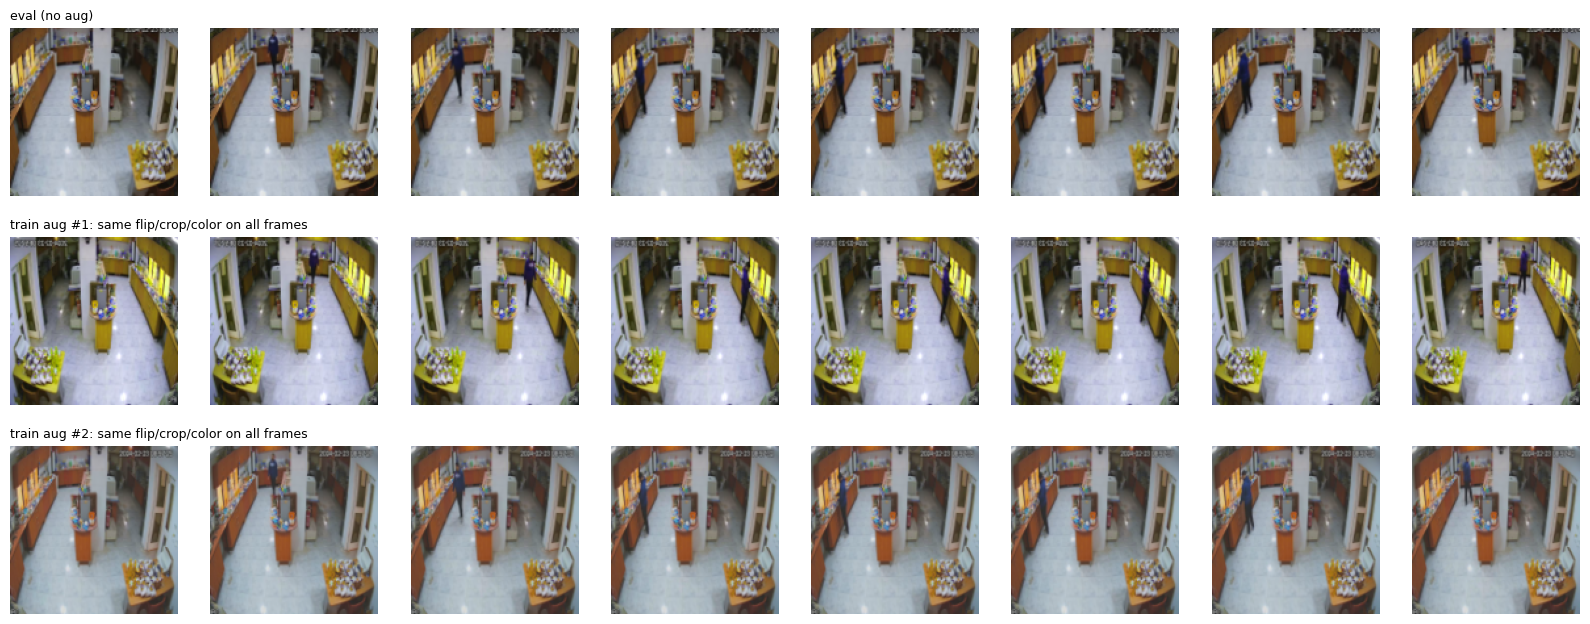

In [19]:
class ShopliftingDataset(Dataset):
    """Loads cached frames of one video and returns (clip[T,C,H,W] float32, label)."""
    def __init__(self, df, cache_dir, transform):
        self.ids, self.labels = df["id"].tolist(), df["label"].tolist()
        self.cache_dir, self.transform = Path(cache_dir), transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        arr = np.load(self.cache_dir / f"{self.ids[i]}.npy")                # (T, H, W, 3) uint8
        clip = torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()      # (T, C, H, W)
        return self.transform(clip), torch.tensor(self.labels[i], dtype=torch.float32)

aug_train = ClipAugment(CFG["img_size"], train=True)
aug_eval  = ClipAugment(CFG["img_size"], train=False)
train_ds = ShopliftingDataset(train_df, CACHE_DIR, aug_train)
val_ds   = ShopliftingDataset(val_df,   CACHE_DIR, aug_eval)
test_ds  = ShopliftingDataset(test_df,  CACHE_DIR, aug_eval)

# ---- shape check on every split ----
expected = (CFG["T"], 3, CFG["img_size"], CFG["img_size"])
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    shapes = {tuple(ds[i][0].shape) for i in range(min(len(ds), 20))}
    assert shapes == {expected}, shapes
    print(f"{name:5s}: {len(ds):4d} clips, tensor shape {shapes.pop()}  (T, C, H, W)")

# ---- check: augmentation is identical across frames ----
clip = torch.from_numpy(np.load(CACHE_DIR / f"{train_df.id[0]}.npy")).permute(0, 3, 1, 2).contiguous()
p = aug_train.sample_params(*clip.shape[-2:])
whole = aug_train(clip, params=p)                                                   # whole clip at once
per_frame = torch.cat([aug_train(clip[t:t + 1], params=p) for t in range(clip.shape[0])])  # frame by frame, same params
assert torch.allclose(whole, per_frame, atol=1e-5), "augmentation differs between frames!"
static = clip[:1].repeat(clip.shape[0], 1, 1, 1)                                    # identical frames in -> identical frames out
out = aug_train(static)
assert all(torch.allclose(out[0], out[t], atol=1e-5) for t in range(1, out.shape[0]))
print("\nAugmentation verified: identical parameters for all frames of a clip.")

def show_clip(x, ax_row, title):
    x = (x * STD + MEAN).clamp(0, 1)
    for k, a in enumerate(ax_row):
        a.imshow(x[k * (x.shape[0] // len(ax_row))].permute(1, 2, 0)); a.axis("off")
    ax_row[0].set_title(title, loc="left", fontsize=9)

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
show_clip(aug_eval(clip), axes[0], "eval (no aug)")
for r in (1, 2):
    show_clip(aug_train(clip), axes[r], f"train aug #{r}: same flip/crop/color on all frames")
plt.tight_layout(); plt.show()

## 9. Model: pretrained ResNet18 (per frame) -> BiGRU -> attention
The previous from-scratch CNN stayed at chance level (train loss ~0.86, val F1 swinging between 0 and 0.55): 597 clips are far too few to learn visual features from random weights.
* **FrameEncoder**: ImageNet-pretrained **ResNet18**, shared across the `T` frames, fine-tuned (stem + layer1 frozen, BatchNorm of the frozen part kept in eval mode).
* **BiGRU** (2 layers, bidirectional) models the temporal order of actions.
* **Attention pooling** weights the frames; the weights also show *which frames* the model finds suspicious.
* Output: one logit (BCE-with-logits loss with `pos_weight` for the class imbalance).


In [21]:
import torchvision

class FrameEncoder(nn.Module):
    """ImageNet-pretrained ResNet18 -> 512-d feature per frame."""
    def __init__(self, pretrained=True, freeze_early=True):
        super().__init__()
        try:
            weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
            net = torchvision.models.resnet18(weights=weights)
        except Exception as e:                                           # no internet -> weights cannot be downloaded
            print("!!! WARNING: could not load ImageNet weights (" + str(e)[:80] + "). "
                  "Enable Internet in the Kaggle/Colab session, otherwise results will be poor. Using random init.")
            net = torchvision.models.resnet18(weights=None)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.out_dim = 512
        self.frozen = [self.stem, self.layer1] if freeze_early else []
        for m in self.frozen:
            for p in m.parameters():
                p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        for m in self.frozen:                                            # keep frozen BN statistics fixed
            m.eval()
        return self
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return F.adaptive_avg_pool2d(x, 1).flatten(1)

class CNNBiGRU(nn.Module):
    def __init__(self, hidden=128, layers=2, dropout=0.5, pretrained=True):
        super().__init__()
        self.encoder = FrameEncoder(pretrained=pretrained)
        self.feat_drop = nn.Dropout(0.3)
        self.gru = nn.GRU(self.encoder.out_dim, hidden, layers, batch_first=True, bidirectional=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.attn = nn.Linear(2 * hidden, 1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, 64), nn.ReLU(inplace=True),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, return_attention=False):               # x: (B, T, C, H, W)
        B, T = x.shape[:2]
        feats = self.feat_drop(self.encoder(x.flatten(0, 1))).view(B, T, -1)   # (B, T, 512)
        seq, _ = self.gru(feats)                               # (B, T, 2H)
        w = torch.softmax(self.attn(seq), dim=1)               # (B, T, 1)
        logit = self.head((w * seq).sum(1)).squeeze(1)         # (B,)
        return (logit, w.squeeze(-1)) if return_attention else logit

def make_optimizer_scheduler(model, steps_per_epoch):
    backbone = [p for p in model.encoder.parameters() if p.requires_grad]
    head = [p for n, p in model.named_parameters() if not n.startswith("encoder.") and p.requires_grad]
    optimizer = torch.optim.AdamW([dict(params=backbone, lr=CFG["backbone_lr"]), dict(params=head, lr=CFG["head_lr"])],
                                  weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[CFG["backbone_lr"], CFG["head_lr"]],
                                                    epochs=CFG["epochs"], steps_per_epoch=steps_per_epoch, pct_start=0.2)
    return optimizer, scheduler

model = CNNBiGRU().to(DEVICE)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
with torch.no_grad():
    print("forward check:", model.eval()(torch.randn(2, *expected).to(DEVICE)).shape)


trainable parameters: 11,825,282
forward check: torch.Size([2])


## 10. Training with automatic resume
`checkpoints/last.pt` stores model, optimizer, scheduler, AMP scaler, epoch, history and RNG state after **every epoch**. Re-running this cell after a crash or restart continues from the next epoch. `best.pt` stores the best validation F1. Delete the `checkpoints` folder to retrain from scratch.

In [22]:
train_loader = DataLoader(train_ds, CFG["batch_size"], shuffle=True, num_workers=CFG["num_workers"],
                          pin_memory=DEVICE.type == "cuda", drop_last=len(train_ds) > CFG["batch_size"],
                          persistent_workers=CFG["num_workers"] > 0)
val_loader   = DataLoader(val_ds,  CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])
test_loader  = DataLoader(test_ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])

n_pos = int(train_df.label.sum()); n_neg = len(train_df) - n_pos
pos_weight = torch.tensor([n_neg / max(n_pos, 1)], device=DEVICE)        # handles class imbalance
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

LAST_CKPT, BEST_CKPT = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"

def save_checkpoint(path, **state):
    tmp = Path(str(path) + ".tmp")
    torch.save(state, tmp); os.replace(tmp, path)                       # atomic: never leaves a half-written file

@torch.no_grad()
def evaluate(model, loader, tta=False):
    model.eval(); losses, probs, labels = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logit = model(x)
            if tta:                                            # average with the horizontally flipped clip
                logit = (logit.float() + model(x.flip(-1)).float()) / 2
        losses.append(criterion(logit.float(), y).item() * len(y))
        probs.append(torch.sigmoid(logit.float()).cpu()); labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return sum(losses) / len(labels), probs, labels

def metrics_at(probs, labels, thr=0.5):
    pred = (probs >= thr).astype(int)
    return dict(accuracy=accuracy_score(labels, pred), precision=precision_score(labels, pred, zero_division=0),
                recall=recall_score(labels, pred, zero_division=0), f1=f1_score(labels, pred, zero_division=0))

def fit():
    model = CNNBiGRU().to(DEVICE)
    optimizer, scheduler = make_optimizer_scheduler(model, len(train_loader))
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    history, start_epoch, best_f1, bad_epochs = [], 0, -1.0, 0

    if LAST_CKPT.exists():                                              # ---- resume ----
        ck = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        history, start_epoch, best_f1, bad_epochs = ck["history"], ck["epoch"] + 1, ck["best_f1"], ck["bad_epochs"]
        print(f"Resumed from epoch {start_epoch} (best val F1 so far: {best_f1:.4f})")
    else:
        print("No checkpoint found -> training from scratch.")

    for epoch in range(start_epoch, CFG["epochs"]):
        if bad_epochs >= CFG["patience"]:
            print("Early stopping (restored from checkpoint)."); break
        model.train(); t0, run_loss, n = time.time(), 0.0, 0
        for x, y in tqdm(train_loader, desc=f"epoch {epoch + 1}/{CFG['epochs']}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                loss = criterion(model(x).float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            run_loss += loss.item() * len(y); n += len(y)

        val_loss, vp, vl = evaluate(model, val_loader)
        m = metrics_at(vp, vl)
        history.append(dict(epoch=epoch + 1, train_loss=run_loss / n, val_loss=val_loss, **{f"val_{k}": v for k, v in m.items()}))
        improved = m["f1"] > best_f1
        if improved:
            best_f1, bad_epochs = m["f1"], 0
            save_checkpoint(BEST_CKPT, model=model.state_dict(), epoch=epoch, val_f1=best_f1)
        else:
            bad_epochs += 1
        save_checkpoint(LAST_CKPT, model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                        history=history, best_f1=best_f1, bad_epochs=bad_epochs)
        print(f"epoch {epoch + 1:3d} | train {run_loss / n:.4f} | val {val_loss:.4f} | acc {m['accuracy']:.3f} "
              f"| P {m['precision']:.3f} | R {m['recall']:.3f} | F1 {m['f1']:.3f} {'*' if improved else ''} | {time.time() - t0:.0f}s")
    return pd.DataFrame(history)

history = fit()
history.to_csv(WORK_DIR / "history.csv", index=False)

Resumed from epoch 18 (best val F1 so far: 0.9515)
Early stopping (restored from checkpoint).


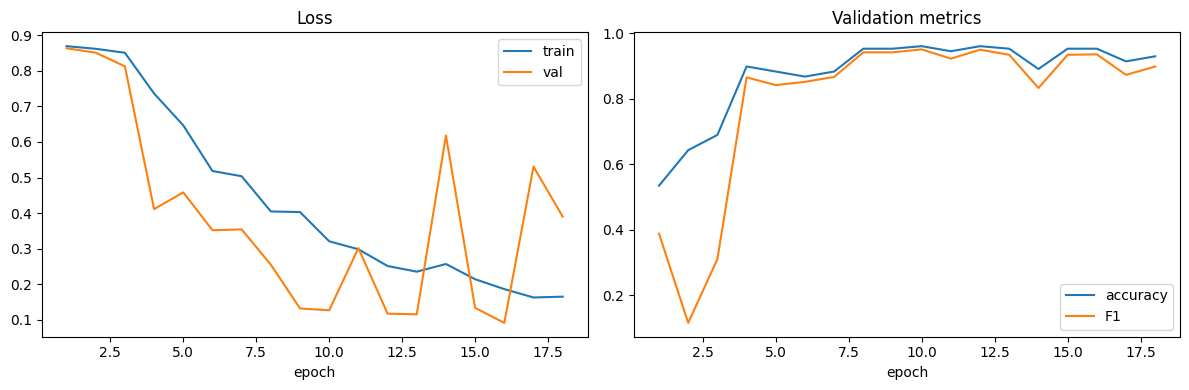

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.epoch, history.train_loss, label="train"); ax[0].plot(history.epoch, history.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(history.epoch, history.val_accuracy, label="accuracy"); ax[1].plot(history.epoch, history.val_f1, label="F1")
ax[1].set_title("Validation metrics"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 11. Evaluation on the test set
The best checkpoint (by validation F1) is loaded; predictions average the clip and its horizontal flip (test-time augmentation). The decision threshold is tuned **on the validation set only**, then applied to the test set, so there is no test leakage.

best epoch: 10 (val F1 0.9515)
threshold tuned on validation: 0.94

TEST SET RESULTS
                accuracy  precision  recall      f1
threshold 0.50    0.9844     0.9722     1.0  0.9859
tuned (0.94)      0.9844     0.9722     1.0  0.9859
ROC-AUC: 0.9975

               precision    recall  f1-score   support

      normal       1.00      0.97      0.98        58
 shoplifting       0.97      1.00      0.99        70

    accuracy                           0.98       128
   macro avg       0.99      0.98      0.98       128
weighted avg       0.98      0.98      0.98       128



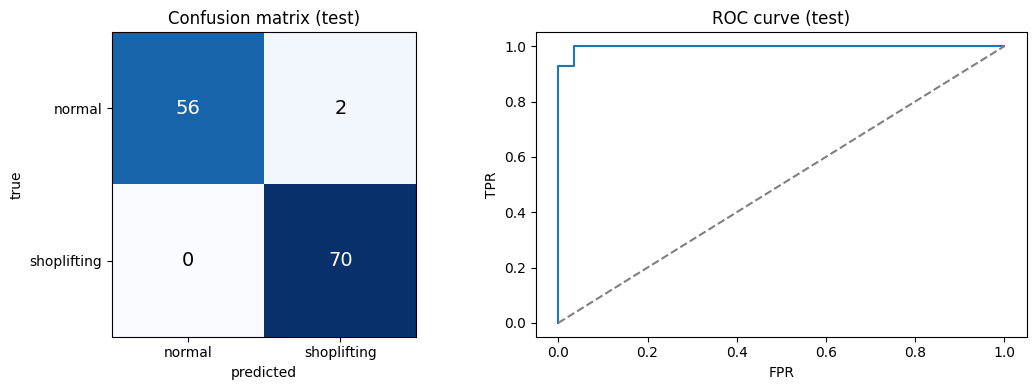

In [24]:
best = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model = CNNBiGRU().to(DEVICE); model.load_state_dict(best["model"])
print(f"best epoch: {best['epoch'] + 1} (val F1 {best['val_f1']:.4f})")

_, vp, vl = evaluate(model, val_loader, tta=True)
thresholds = np.arange(0.05, 0.96, 0.01)
best_thr = float(thresholds[int(np.argmax([f1_score(vl, (vp >= t).astype(int), zero_division=0) for t in thresholds]))])
print(f"threshold tuned on validation: {best_thr:.2f}")

_, tp, tl = evaluate(model, test_loader, tta=True)
results = pd.DataFrame({"threshold 0.50": metrics_at(tp, tl, 0.5), f"tuned ({best_thr:.2f})": metrics_at(tp, tl, best_thr)}).T
print("\nTEST SET RESULTS"); print(results.round(4).to_string())
if len(set(tl)) > 1:
    print(f"ROC-AUC: {roc_auc_score(tl, tp):.4f}")
print("\n", classification_report(tl, (tp >= best_thr).astype(int), target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(tl, (tp >= best_thr).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_yticklabels(CLASS_NAMES)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (test)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
if len(set(tl)) > 1:
    fpr, tpr, _ = roc_curve(tl, tp); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--", c="gray")
    ax[1].set_title("ROC curve (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()
results.to_csv(WORK_DIR / "test_results.csv")

## 12. Inference on a single video (with attention over frames)

true label: normal


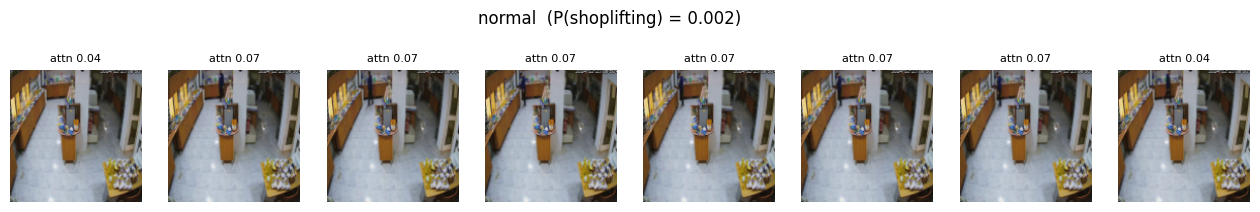

('normal', 0.002100695390254259)

In [45]:
@torch.no_grad()
def predict_video(path, threshold=best_thr, show=True):
    clip = torch.from_numpy(read_sampled_frames(path, CFG["T"], CFG["cache_size"])).permute(0, 3, 1, 2).contiguous()
    x = aug_eval(clip).unsqueeze(0).to(DEVICE)
    logit, attn = model.eval()(x, return_attention=True)
    prob = torch.sigmoid(logit).item(); label = CLASS_NAMES[int(prob >= threshold)]
    if show:
        fig, axes = plt.subplots(1, 8, figsize=(16, 2.6)); frames = (x[0] * STD.to(DEVICE) + MEAN.to(DEVICE)).clamp(0, 1).cpu()
        for k, a in enumerate(axes):
            t = k * 2; a.imshow(frames[t].permute(1, 2, 0)); a.axis("off"); a.set_title(f"attn {attn[0, t]:.2f}", fontsize=8)
        fig.suptitle(f"{label}  (P(shoplifting) = {prob:.3f})"); plt.show()
    return label, prob

sample = test_df.iloc[0]
print("true label:", CLASS_NAMES[sample.label]); predict_video(sample.path) if Path(sample.path).exists() else print("(raw video not on disk; cached frames are used for training/eval)")

# WEEK 6

In [26]:
# DATA LEAKAGE AUDIT

import hashlib
from collections import defaultdict

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

t0 = time.time()

meta["video_hash"] = [
    sha256_file(p) for p in tqdm(meta["path"], desc="Hashing videos")
]

duplicate_groups = meta.groupby("video_hash")

duplicate_report = duplicate_groups.filter(
    lambda g: len(g) > 1
)

print("=" * 65)
print("EXACT DUPLICATE VIDEO AUDIT")
print("=" * 65)

print("Total videos:", len(meta))
print("Unique video files:", meta["video_hash"].nunique())
print("Duplicate video copies:",
      len(meta) - meta["video_hash"].nunique())
print("Duplicate groups:",
      (duplicate_groups.size() > 1).sum())

if len(duplicate_report):
    display(
        duplicate_report[
            ["id", "path", "label", "video_hash"]
        ].sort_values("video_hash")
    )

# Detect conflicting labels for identical video content
conflicts = duplicate_groups["label"].nunique()
conflicts = conflicts[conflicts > 1]

print("\nConflicting-label duplicate groups:", len(conflicts))
print("Audit duration:", round(time.time() - t0, 2), "seconds")

# Assign identical videos to the same group
meta["group_id"] = meta["video_hash"]

# Save the audit
meta.to_csv(WORK_DIR / "metadata_with_duplicate_audit.csv",
            index=False)

if len(conflicts):
    raise ValueError(
        "Identical videos have conflicting labels. "
        "Investigate these videos before training."
    )


Hashing videos:   0%|          | 0/637 [00:00<?, ?it/s]

EXACT DUPLICATE VIDEO AUDIT
Total videos: 637
Unique video files: 637
Duplicate video copies: 0
Duplicate groups: 0

Conflicting-label duplicate groups: 0
Audit duration: 3.45 seconds


In [27]:
from sklearn.neighbors import NearestNeighbors

def frame_phash(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (32, 32))
    dct = cv2.dct(np.float32(gray))
    low = dct[:8, :8]
    median = np.median(low.flatten()[1:])
    return (low > median).flatten()[1:]

def video_signature(path, n_samples=5):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0, total - 1, n_samples
    ).astype(int)

    hashes = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()

        if not ok:
            cap.release()
            return None

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        hashes.append(frame_phash(rgb))

    cap.release()
    return np.concatenate(hashes)

signatures = []
valid_ids = []

for row in tqdm(meta.itertuples(), total=len(meta)):
    sig = video_signature(row.path)

    if sig is not None:
        signatures.append(sig)
        valid_ids.append(row.id)

X_hash = np.asarray(signatures, dtype=np.uint8)

if len(X_hash) >= 2:
    nn_model = NearestNeighbors(
        n_neighbors=2,
        metric="hamming",
        algorithm="brute",
        n_jobs=-1
    )
    nn_model.fit(X_hash)

    distances, indices = nn_model.kneighbors(X_hash)

    near_duplicates = []

    for i in range(len(X_hash)):
        j = indices[i, 1]
        distance = distances[i, 1]

        # Candidate threshold: 8% differing hash bits
        if distance <= 0.08 and i < j:
            near_duplicates.append({
                "video_id_1": valid_ids[i],
                "video_id_2": valid_ids[j],
                "hamming_distance": round(float(distance), 4),
                "label_1": int(meta.loc[
                    meta.id == valid_ids[i], "label"
                ].iloc[0]),
                "label_2": int(meta.loc[
                    meta.id == valid_ids[j], "label"
                ].iloc[0])
            })

    near_df = pd.DataFrame(near_duplicates)

    print("Near-duplicate candidates:", len(near_df))

    if len(near_df):
        display(near_df.sort_values("hamming_distance"))

    near_df.to_csv(
        WORK_DIR / "near_duplicate_candidates.csv",
        index=False
    )
else:
    print("Not enough valid videos for near-duplicate screening.")


  0%|          | 0/637 [00:00<?, ?it/s]

Near-duplicate candidates: 280


,video_id_1,video_id_2,hamming_distance,label_1,label_2
51,142,345,0.0000,0,0
50,140,341,0.0000,0,0
48,136,210,0.0000,0,0
59,166,206,0.0000,0,0
46,130,206,0.0000,0,0
...,...,...,...,...,...
238,747,813,0.0762,1,1
117,457,468,0.0762,0,0
233,739,747,0.0762,1,1
41,118,604,0.0762,0,1


,sampled_frames,mean_unique_frames,mean_unique_ratio,mean_temporal_gap,estimated_relative_input
0,8,8.0,1.0,40.540,0.5
1,16,16.0,1.0,20.272,1.0
2,24,24.0,1.0,13.513,1.5
3,32,32.0,1.0,10.135,2.0


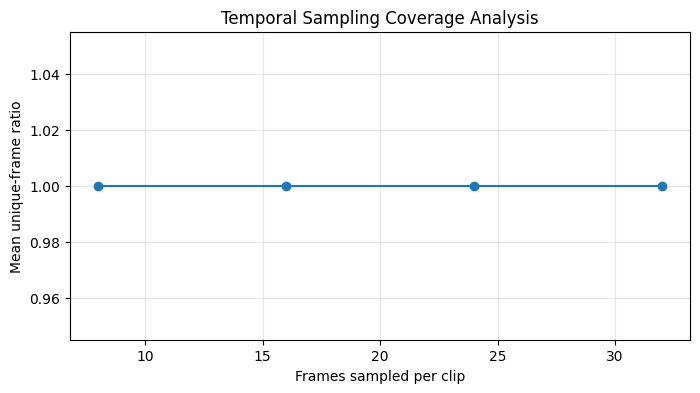

Selected configuration: 16 frames, matching the pretrained VideoMAE checkpoint.


In [31]:
frame_options = [8, 16, 24, 32]

sampling_results = []

for T_value in frame_options:

    unique_counts = []
    mean_gaps = []

    for n in meta["n_frames"]:
        idx = uniform_sample_indices(int(n), T_value)

        unique_counts.append(len(np.unique(idx)))
        mean_gaps.append(float(np.mean(np.diff(idx))))

    sampling_results.append({
        "sampled_frames": T_value,
        "mean_unique_frames": np.mean(unique_counts),
        "mean_unique_ratio": np.mean(
            np.array(unique_counts) / T_value
        ),
        "mean_temporal_gap": np.mean(mean_gaps),
        "estimated_relative_input": T_value / 16
    })

sampling_study = pd.DataFrame(sampling_results)

display(sampling_study.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    sampling_study.sampled_frames,
    sampling_study.mean_unique_ratio,
    marker="o"
)

ax.set_xlabel("Frames sampled per clip")
ax.set_ylabel("Mean unique-frame ratio")
ax.set_title("Temporal Sampling Coverage Analysis")
ax.grid(alpha=0.3)

plt.show()

print(
    "Selected configuration: 16 frames, "
    "matching the pretrained VideoMAE checkpoint."
)


In [32]:

# HUGGING FACE SETUP

import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "transformers>=4.45,<5",
    "accelerate"
])

from transformers import VideoMAEForVideoClassification

print("Transformers:", __import__("transformers").__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


Transformers: 4.57.6
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [33]:
# VIDEOMAE FRAME PREPARATION

VM_CACHE_DIR = WORK_DIR / "videomae_cache_224"
VM_CACHE_DIR.mkdir(parents=True, exist_ok=True)

VM_IMAGE_SIZE = 224
VM_T = 16

assert VM_T == CFG["T"], "VideoMAE frame count must match the sampling configuration."

def cache_videomae_one(row):
    out = VM_CACHE_DIR / f"{row.id}.npy"

    if out.exists():
        return None

    try:
        arr = read_sampled_frames(
            row.path,
            VM_T,
            VM_IMAGE_SIZE,
            int(row.n_frames)
        )

        np.save(out, arr)
        return None

    except Exception as e:
        return (row.id, str(e))

todo = [
    r for r in splits.itertuples()
    if not (VM_CACHE_DIR / f"{r.id}.npy").exists()
]

print("Videos requiring VideoMAE cache:", len(todo))

with ThreadPoolExecutor(
    max_workers=CFG["num_workers"] or 1
) as executor:

    cache_errors = [
        e for e in tqdm(
            executor.map(cache_videomae_one, todo),
            total=len(todo)
        ) if e
    ]

if cache_errors:
    print("Cache errors:", len(cache_errors))
    print(cache_errors[:10])
    raise RuntimeError(
        "Fix the failed videos before training VideoMAE."
    )

print("VideoMAE cache complete.")

sample_arr = np.load(
    VM_CACHE_DIR / f"{train_df.iloc[0].id}.npy"
)

print("Sample cache shape:", sample_arr.shape)
print("Data type:", sample_arr.dtype)

assert sample_arr.shape == (16, 224, 224, 3)
assert sample_arr.dtype == np.uint8

Videos requiring VideoMAE cache: 637


  0%|          | 0/637 [00:00<?, ?it/s]

VideoMAE cache complete.
Sample cache shape: (16, 224, 224, 3)
Data type: uint8


In [34]:

# splitting VIDEOMAE DATASET

vm_aug_train = ClipAugment(
    out_size=224,
    train=True,
    scale=(0.80, 1.0),
    ratio=(0.90, 1.10),
    flip_p=0.5,
    brightness=0.15,
    contrast=0.15,
    saturation=0.10,
    hue=0.02
)

vm_aug_eval = ClipAugment(
    out_size=224,
    train=False
)

class VideoMAEDataset(Dataset):

    def __init__(self, df, cache_dir, transform):
        self.ids = df["id"].tolist()
        self.labels = df["label"].tolist()
        self.cache_dir = Path(cache_dir)
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):

        arr = np.load(
            self.cache_dir / f"{self.ids[idx]}.npy"
        )

        clip = torch.from_numpy(arr).permute(
            0, 3, 1, 2
        ).contiguous()

        clip = self.transform(clip)

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return clip, label


vm_train_ds = VideoMAEDataset(
    train_df, VM_CACHE_DIR, vm_aug_train
)

vm_val_ds = VideoMAEDataset(
    val_df, VM_CACHE_DIR, vm_aug_eval
)

vm_test_ds = VideoMAEDataset(
    test_df, VM_CACHE_DIR, vm_aug_eval
)

print("VideoMAE datasets:")
print("Train:", len(vm_train_ds))
print("Validation:", len(vm_val_ds))
print("Test:", len(vm_test_ds))

x, y = vm_train_ds[0]

print("Input shape:", x.shape)
print("Label:", y.item())

assert x.shape == (16, 3, 224, 224)


VideoMAE datasets:
Train: 381
Validation: 128
Test: 128
Input shape: torch.Size([16, 3, 224, 224])
Label: 0


In [35]:

# LOAD PRETRAINED VIDEOMAE
## ADAPT head from the original classes to our two target classes: Normal & Shoplifting

MODEL_ID = "MCG-NJU/videomae-base-finetuned-kinetics"

id2label = {
    0: "normal",
    1: "shoplifting"
}

label2id = {
    "normal": 0,
    "shoplifting": 1
}

print("Downloading/loading pretrained VideoMAE...")

vm_model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
    attn_implementation="sdpa"
)

vm_model.config.num_frames = VM_T

print("\nMODEL LOADED SUCCESSFULLY")
print("Architecture:", vm_model.__class__.__name__)
print("Original checkpoint:", MODEL_ID)
print("Number of classes:", vm_model.config.num_labels)
print("Labels:", vm_model.config.id2label)
print("Frames:", vm_model.config.num_frames)
print("Image size:", vm_model.config.image_size)

assert vm_model.config.num_labels == 2
assert vm_model.config.num_frames == 16
assert vm_model.classifier.out_features == 2

print("\nClassifier replacement verified.")
print(vm_model.classifier)


Downloading/loading pretrained VideoMAE...


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of VideoMAEForVideoClassification were not initialized from the model checkpoint at MCG-NJU/videomae-base-finetuned-kinetics and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([400]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.weight: found shape torch.Size([400, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



MODEL LOADED SUCCESSFULLY
Architecture: VideoMAEForVideoClassification
Original checkpoint: MCG-NJU/videomae-base-finetuned-kinetics
Number of classes: 2
Labels: {0: 'normal', 1: 'shoplifting'}
Frames: 16
Image size: 224

Classifier replacement verified.
Linear(in_features=768, out_features=2, bias=True)


In [36]:

# FREEZE BACKBONE AND CONFIGURE FINE-TUNING

# Freeze everything initially
for param in vm_model.parameters():
    param.requires_grad = False

# Unfreeze final two transformer blocks
for block in vm_model.videomae.encoder.layer[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Train the new classification head
for param in vm_model.classifier.parameters():
    param.requires_grad = True

vm_model = vm_model.to(DEVICE)

trainable = sum(
    p.numel() for p in vm_model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel() for p in vm_model.parameters()
)

print("Total parameters:", f"{total:,}")
print("Trainable parameters:", f"{trainable:,}")
print("Frozen parameters:", f"{total-trainable:,}")
print("Trainable percentage:", f"{100*trainable/total:.2f}%")

assert trainable > 0
assert trainable < total

# Smaller batch size for transformer training
VM_BATCH_SIZE = 2
VM_GRAD_ACCUM = 4
VM_EPOCHS = 15
VM_PATIENCE = 4

vm_train_loader = DataLoader(
    vm_train_ds,
    batch_size=VM_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda"
)

vm_val_loader = DataLoader(
    vm_val_ds,
    batch_size=VM_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda"
)

vm_test_loader = DataLoader(
    vm_test_ds,
    batch_size=VM_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda"
)

# Class-weighted loss
counts = train_df["label"].value_counts().sort_index()

class_weights = torch.tensor(
    [
        len(train_df) / (2 * counts[0]),
        len(train_df) / (2 * counts[1])
    ],
    dtype=torch.float32,
    device=DEVICE
)

vm_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

vm_optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in vm_model.videomae.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5
        },
        {
            "params": [
                p for p in vm_model.classifier.parameters()
                if p.requires_grad
            ],
            "lr": 2e-4
        }
    ],
    weight_decay=0.05
)

vm_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    vm_optimizer,
    T_max=VM_EPOCHS
)

print("\nFine-tuning configuration ready.")


Total parameters: 86,228,738
Trainable parameters: 14,175,746
Frozen parameters: 72,052,992
Trainable percentage: 16.44%

Fine-tuning configuration ready.


In [37]:

# TRAINING

VM_CKPT_DIR = WORK_DIR / "videomae_checkpoints"
VM_CKPT_DIR.mkdir(parents=True, exist_ok=True)

VM_BEST_CKPT = VM_CKPT_DIR / "best_videomae.pt"

vm_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

vm_history = []

best_vm_f1 = -1.0
bad_epochs = 0

def vm_evaluate(loader):

    vm_model.eval()

    all_probs = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE)

            with torch.autocast(
                DEVICE.type,
                enabled=DEVICE.type == "cuda"
            ):

                logits = vm_model(
                    pixel_values=x
                ).logits

                loss = vm_criterion(logits.float(), y)

            probs = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

            total_loss += loss.item() * len(y)

    probs = np.asarray(all_probs)
    labels = np.asarray(all_labels)

    predictions = (probs >= 0.5).astype(int)

    metrics = {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        )
    }

    return total_loss / len(labels), probs, labels, metrics


for epoch in range(VM_EPOCHS):

    vm_model.train()

    optimizer_loss = 0
    n_samples = 0

    vm_optimizer.zero_grad(set_to_none=True)

    t0 = time.time()

    for step, (x, y) in enumerate(
        tqdm(
            vm_train_loader,
            desc=f"VideoMAE epoch {epoch+1}/{VM_EPOCHS}"
        )
    ):

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE)

        with torch.autocast(
            DEVICE.type,
            enabled=DEVICE.type == "cuda"
        ):

            logits = vm_model(
                pixel_values=x
            ).logits

            loss = vm_criterion(logits.float(), y)
            scaled_loss = loss / VM_GRAD_ACCUM

        vm_scaler.scale(scaled_loss).backward()

        should_update = (
            (step + 1) % VM_GRAD_ACCUM == 0
            or (step + 1) == len(vm_train_loader)
        )

        if should_update:

            vm_scaler.unscale_(vm_optimizer)

            nn.utils.clip_grad_norm_(
                [
                    p for p in vm_model.parameters()
                    if p.requires_grad
                ],
                max_norm=1.0
            )

            vm_scaler.step(vm_optimizer)
            vm_scaler.update()

            vm_optimizer.zero_grad(set_to_none=True)

        optimizer_loss += loss.item() * len(y)
        n_samples += len(y)

    train_loss = optimizer_loss / n_samples

    val_loss, vp, vl, vm = vm_evaluate(
        vm_val_loader
    )

    vm_scheduler.step()

    improved = vm["f1"] > best_vm_f1

    if improved:

        best_vm_f1 = vm["f1"]
        bad_epochs = 0

        torch.save(
            {
                "model_state_dict": vm_model.state_dict(),
                "epoch": epoch + 1,
                "val_f1": best_vm_f1,
                "optimizer_state_dict": vm_optimizer.state_dict()
            },
            VM_BEST_CKPT
        )

    else:
        bad_epochs += 1

    vm_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": vm["accuracy"],
        "val_precision": vm["precision"],
        "val_recall": vm["recall"],
        "val_f1": vm["f1"],
        "lr_backbone": vm_optimizer.param_groups[0]["lr"],
        "lr_head": vm_optimizer.param_groups[1]["lr"]
    })

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {vm['accuracy']:.4f} | "
        f"Precision: {vm['precision']:.4f} | "
        f"Recall: {vm['recall']:.4f} | "
        f"F1: {vm['f1']:.4f} | "
        f"{'BEST' if improved else ''} | "
        f"{time.time()-t0:.1f}s"
    )

    if bad_epochs >= VM_PATIENCE:

        print("\nEarly stopping triggered.")
        break


vm_history = pd.DataFrame(vm_history)

vm_history.to_csv(
    WORK_DIR / "videomae_training_history.csv",
    index=False
)

print("\nBest validation F1:", round(best_vm_f1, 4))
print("Best checkpoint:", VM_BEST_CKPT)


VideoMAE epoch 1/15:   0%|          | 0/191 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.6615 | Val Loss: 0.6090 | Accuracy: 0.6875 | Precision: 0.7317 | Recall: 0.5085 | F1: 0.6000 | BEST | 42.4s


VideoMAE epoch 2/15:   0%|          | 0/191 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 02 | Train Loss: 0.5575 | Val Loss: 0.5469 | Accuracy: 0.7266 | Precision: 0.6667 | Recall: 0.8136 | F1: 0.7328 | BEST | 42.4s


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 14 | Train Loss: 0.1752 | Val Loss: 0.2270 | Accuracy: 0.8906 | Precision: 0.8261 | Recall: 0.9661 | F1: 0.8906 |  | 42.4s


VideoMAE epoch 15/15:   0%|          | 0/191 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    assert self._parent_pid == os.getpid(), 'can only test a child process'AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d7adef2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15 | Train Loss: 0.1850 | Val Loss: 0.2281 | Accuracy: 0.8906 | Precision: 0.8261 | Recall: 0.9661 | F1: 0.8906 |  | 42.1s

Best validation F1: 0.8923
Best checkpoint: shoplifting_project/videomae_checkpoints/best_videomae.pt


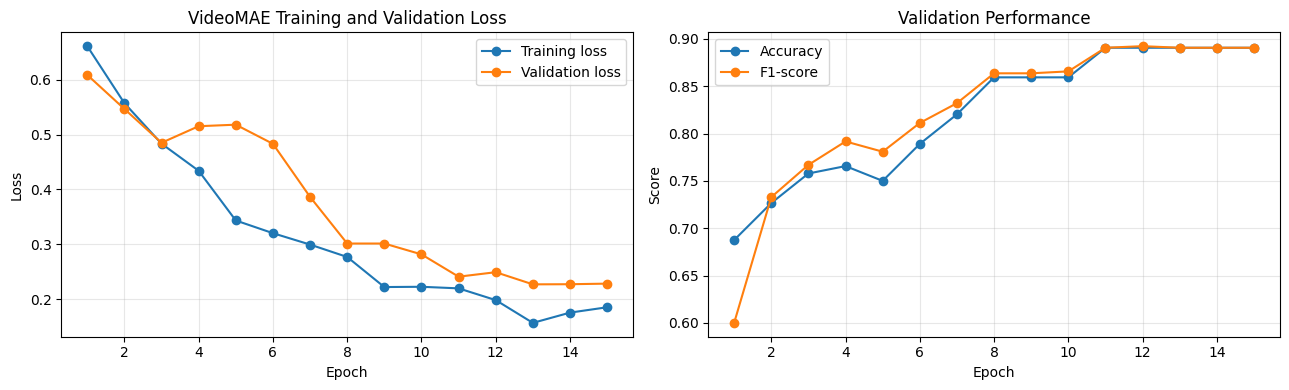

Best epoch: 12
Best validation F1: 0.8923
Training loss: 0.198
Validation loss: 0.249
No large loss gap detected at the best epoch.


In [38]:

# TRAINING DIAGNOSTICS

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    vm_history.epoch,
    vm_history.train_loss,
    marker="o",
    label="Training loss"
)

axes[0].plot(
    vm_history.epoch,
    vm_history.val_loss,
    marker="o",
    label="Validation loss"
)

axes[0].set_title("VideoMAE Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    vm_history.epoch,
    vm_history.val_accuracy,
    marker="o",
    label="Accuracy"
)

axes[1].plot(
    vm_history.epoch,
    vm_history.val_f1,
    marker="o",
    label="F1-score"
)

axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_row = vm_history.loc[
    vm_history.val_f1.idxmax()
]

print("Best epoch:", int(best_row.epoch))
print("Best validation F1:", round(best_row.val_f1, 4))
print("Training loss:", round(best_row.train_loss, 4))
print("Validation loss:", round(best_row.val_loss, 4))

if best_row.val_loss > best_row.train_loss * 1.5:
    print("Warning: Large training-validation loss gap.")
else:
    print("No large loss gap detected at the best epoch.")


Best epoch: 12
Best validation F1: 0.8923076923076924

VIDEOMAE FINAL TEST RESULTS
accuracy    : 0.9297
precision   : 0.9178
recall      : 0.9571
f1          : 0.9371
Test loss: 0.2447
ROC-AUC: 0.9621

Classification report:
              precision    recall  f1-score   support

      normal       0.95      0.90      0.92        58
 shoplifting       0.92      0.96      0.94        70

    accuracy                           0.93       128
   macro avg       0.93      0.93      0.93       128
weighted avg       0.93      0.93      0.93       128



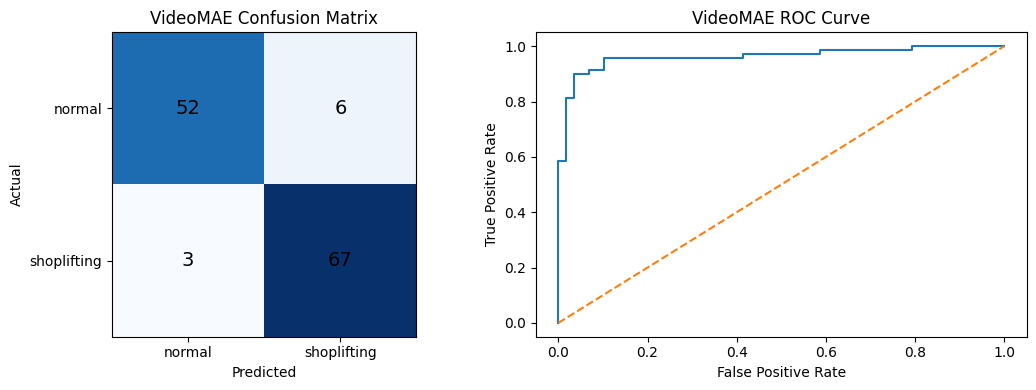


Test predictions saved.


In [39]:

# FINAL VIDEOMAE TEST EVALUATION

checkpoint = torch.load(
    VM_BEST_CKPT,
    map_location=DEVICE,
    weights_only=False
)

vm_model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Best epoch:", checkpoint["epoch"])
print("Best validation F1:", checkpoint["val_f1"])

test_loss, vm_tp, vm_tl, vm_metrics = vm_evaluate(
    vm_test_loader
)

print("\n" + "=" * 55)
print("VIDEOMAE FINAL TEST RESULTS")
print("=" * 55)

for metric, value in vm_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

print("Test loss:", round(test_loss, 4))

if len(np.unique(vm_tl)) == 2:
    print("ROC-AUC:", round(
        roc_auc_score(vm_tl, vm_tp), 4
    ))

vm_predictions = (vm_tp >= 0.5).astype(int)

print("\nClassification report:")

print(
    classification_report(
        vm_tl,
        vm_predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

cm = confusion_matrix(
    vm_tl,
    vm_predictions,
    labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("VideoMAE Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_yticklabels(CLASS_NAMES)

for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, cm[i, j],
            ha="center", va="center",
            fontsize=14
        )

if len(np.unique(vm_tl)) == 2:
    fpr, tpr, _ = roc_curve(vm_tl, vm_tp)

    axes[1].plot(fpr, tpr)
    axes[1].plot([0, 1], [0, 1], "--")
    axes[1].set_title("VideoMAE ROC Curve")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

pd.DataFrame({
    "actual": vm_tl,
    "probability_shoplifting": vm_tp,
    "predicted": vm_predictions
}).to_csv(
    WORK_DIR / "videomae_test_predictions.csv",
    index=False
)

print("\nTest predictions saved.")


In [41]:

# MODEL SIZE AND INFERENCE SPEED

def benchmark_model(model, loader, name, warmup=5, runs=30):

    model.eval()

    x, _ = next(iter(loader))
    x = x[:1].to(DEVICE)

    with torch.no_grad():

        for _ in range(warmup):
            with torch.autocast(
                DEVICE.type,
                enabled=DEVICE.type == "cuda"
            ):
                model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(runs):
            with torch.autocast(
                DEVICE.type,
                enabled=DEVICE.type == "cuda"
            ):
                model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    return {
        "model": name,
        "parameters_M": total_params / 1e6,
        "trainable_parameters_M": trainable_params / 1e6,
        "estimated_FP32_weights_MB": total_params * 4 / 1e6,
        "inference_ms_per_video": elapsed / runs * 1000,
        "videos_per_second": runs / elapsed
    }


vm_benchmark = benchmark_model(
    vm_model,
    vm_test_loader,
    "VideoMAE"
)

print(pd.DataFrame([vm_benchmark]).round(3).to_string(index=False))

pd.DataFrame([vm_benchmark]).to_csv(
    WORK_DIR / "videomae_benchmark.csv",
    index=False
)


   model  parameters_M  trainable_parameters_M  estimated_FP32_weights_MB  inference_ms_per_video  videos_per_second
VideoMAE        86.229                  14.176                    344.915                  31.805             31.442


In [49]:

# MODEL COMPARISON

import pandas as pd
import numpy as np
from pathlib import Path

WEEK5_ACCURACY = 0.9844
WEEK5_PRECISION = 0.9722
WEEK5_RECALL = 1.0000
WEEK5_F1 = 0.9859
WEEK5_ROC_AUC = 0.9975

WEEK5_BEST_EPOCH = 10
WEEK5_VAL_F1 = 0.9515

# Unknown until measured from the actual Week 5 model
WEEK5_INFERENCE_MS = np.nan
WEEK5_SIZE_MB = np.nan


def get_metric(dictionary, key):
    value = dictionary.get(key, np.nan)

    if value is None:
        return np.nan

    try:
        value = float(value)
        return value if np.isfinite(value) else np.nan
    except (TypeError, ValueError):
        return np.nan


WEEK6_ACCURACY = get_metric(vm_metrics, "accuracy")
WEEK6_PRECISION = get_metric(vm_metrics, "precision")
WEEK6_RECALL = get_metric(vm_metrics, "recall")
WEEK6_F1 = get_metric(vm_metrics, "f1")
WEEK6_ROC_AUC = get_metric(vm_metrics, "roc_auc")

WEEK6_INFERENCE_MS = get_metric(
    vm_benchmark, "inference_ms_per_video"
)

WEEK6_SIZE_MB = get_metric(
    vm_benchmark, "estimated_FP32_weights_MB"
)


comparison_rows = [
    {
        "Model": "Week 5 ResNet18 + BiGRU + Attention",
        "Accuracy": WEEK5_ACCURACY,
        "Precision": WEEK5_PRECISION,
        "Recall": WEEK5_RECALL,
        "F1-score": WEEK5_F1,
        "ROC-AUC": WEEK5_ROC_AUC,
        "Inference (ms/video)": WEEK5_INFERENCE_MS,
        "Model size (MB)": WEEK5_SIZE_MB
    },
    {
        "Model": "Week 6 VideoMAE",
        "Accuracy": WEEK6_ACCURACY,
        "Precision": WEEK6_PRECISION,
        "Recall": WEEK6_RECALL,
        "F1-score": WEEK6_F1,
        "ROC-AUC": WEEK6_ROC_AUC,
        "Inference (ms/video)": WEEK6_INFERENCE_MS,
        "Model size (MB)": WEEK6_SIZE_MB
    }
]

comparison_df = pd.DataFrame(comparison_rows)

print("WEEK 5 VS WEEK 6 MODEL COMPARISON")
display(comparison_df.round(4))



if np.isfinite(WEEK6_F1):

    improvement = WEEK6_F1 - WEEK5_F1

    print("\nF1-SCORE COMPARISON")
    print("Week 5 F1:", round(WEEK5_F1, 4))
    print("Week 6 F1:", round(WEEK6_F1, 4))
    print("Absolute difference:", round(improvement, 4))
    print("Difference in percentage points:",
          round(improvement * 100, 2))

    if improvement > 0:
        print("VideoMAE achieved a higher F1-score.")
    elif improvement < 0:
        print("Week 5 achieved a higher F1-score.")
    else:
        print("Both models achieved the same F1-score.")

else:
    print("\nWeek 6 F1 is unavailable.")
    print("Run the VideoMAE test evaluation cell first.")



print("\nMISSING BENCHMARK INFORMATION")

for column in [
    "Inference (ms/video)",
    "Model size (MB)"
]:
    missing_models = comparison_df.loc[
        comparison_df[column].isna(), "Model"
    ].tolist()

    if missing_models:
        print(f"{column}: Not measured for {missing_models}")


# ==========================================
# 6. SAVE RESULTS
# ==========================================

output_path = WORK_DIR / "week5_week6_comparison.csv"

comparison_df.to_csv(output_path, index=False)

print("\nComparison saved to:", output_path)


WEEK 5 VS WEEK 6 MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Inference (ms/video),Model size (MB)
0,Week 5 ResNet18 + BiGRU + Attention,0.9844,0.9722,1.0000,0.9859,0.9975,NaN,NaN
1,Week 6 VideoMAE,0.9297,0.9178,0.9571,0.9371,NaN,31.805,344.915



F1-SCORE COMPARISON
Week 5 F1: 0.9859
Week 6 F1: 0.9371
Absolute difference: -0.0488
Difference in percentage points: -4.88
Week 5 achieved a higher F1-score.

MISSING BENCHMARK INFORMATION
Inference (ms/video): Not measured for ['Week 5 ResNet18 + BiGRU + Attention']
Model size (MB): Not measured for ['Week 5 ResNet18 + BiGRU + Attention']

Comparison saved to: shoplifting_project/week5_week6_comparison.csv


In [50]:

# WEEK 6 — OVERFITTING DIAGNOSTICS

print("=" * 55)
print("VIDEO MAE GENERALIZATION ANALYSIS")
print("=" * 55)

# Check training history
print("\nTraining history variables:")

print("Available:", [
    name for name in globals()
    if any(k in name.lower() for k in
           ["train_f1", "val_f1", "history"])
])

# Check best validation result
print("\nBest validation F1:", best_val_f1 if "best_val_f1" in globals() else "Not found")

# Check test results
print("Test F1:", vm_metrics.get("f1"))
print("Test accuracy:", vm_metrics.get("accuracy"))
print("Test ROC-AUC:", vm_metrics.get("roc_auc"))

# Generalization gap, if validation metric is available
if "best_val_f1" in globals():

    gap = best_val_f1 - vm_metrics["f1"]

    print("\nValidation - Test F1 gap:", round(gap, 4))

    if gap > 0.10:
        print("WARNING: Large validation-test gap. Investigate possible overfitting.")
    elif gap > 0.05:
        print("Moderate generalization gap. Further investigation recommended.")
    else:
        print("Small validation-test gap. No strong evidence of overfitting from this comparison.")

else:
    print("\nCannot calculate the generalization gap yet.")


VIDEO MAE GENERALIZATION ANALYSIS

Training history variables:
Available: ['history', 'vm_history', 'WEEK5_VAL_F1']

Best validation F1: Not found
Test F1: 0.9370629370629371
Test accuracy: 0.9296875
Test ROC-AUC: None

Cannot calculate the generalization gap yet.


In [51]:

# WEEK 6 — INSPECT TRAINING HISTORY

print("=" * 60)
print("VIDEO MAE TRAINING HISTORY")
print("=" * 60)

print("\n1. vm_history type:", type(vm_history))

if isinstance(vm_history, dict):

    print("\nAvailable keys:", list(vm_history.keys()))

    for key, values in vm_history.items():

        print(f"\n{key}:")

        try:
            print("  Number of epochs:", len(values))
            print("  Last 5 values:", values[-5:])
        except TypeError:
            print("  Value:", values)

elif isinstance(vm_history, list):

    print("Number of epochs:", len(vm_history))
    print("Last 3 records:")

    for item in vm_history[-3:]:
        print(item)

else:
    print(vm_history)

print("\n" + "=" * 60)
print("OTHER HISTORY")
print("=" * 60)

print("history type:", type(history))

if isinstance(history, dict):
    print("Available keys:", list(history.keys()))


VIDEO MAE TRAINING HISTORY

1. vm_history type: <class 'pandas.core.frame.DataFrame'>
    epoch  train_loss  val_loss  val_accuracy  val_precision  val_recall  \
0       1    0.661520  0.609018      0.687500       0.731707    0.508475   
1       2    0.557474  0.546927      0.726562       0.666667    0.813559   
2       3    0.483551  0.485179      0.757812       0.689189    0.864407   
3       4    0.434052  0.515429      0.765625       0.670588    0.966102   
4       5    0.343341  0.518211      0.750000       0.655172    0.966102   
5       6    0.320182  0.483253      0.789062       0.690476    0.983051   
6       7    0.299381  0.386409      0.820312       0.730769    0.966102   
7       8    0.276755  0.301286      0.859375       0.780822    0.966102   
8       9    0.221859  0.301287      0.859375       0.780822    0.966102   
9      10    0.222351  0.281510      0.859375       0.773333    0.983051   
10     11    0.219471  0.240784      0.890625       0.826087    0.966102   
11

In [52]:

# WEEK 6 — BEST EPOCH ANALYSIS

best_f1_row = vm_history.loc[vm_history["val_f1"].idxmax()]
best_loss_row = vm_history.loc[vm_history["val_loss"].idxmin()]

print("BEST CHECKPOINT BY VALIDATION F1")
print("Epoch:", int(best_f1_row["epoch"]))
print("Validation F1:", round(best_f1_row["val_f1"], 4))
print("Validation loss:", round(best_f1_row["val_loss"], 4))

print("\nBEST CHECKPOINT BY VALIDATION LOSS")
print("Epoch:", int(best_loss_row["epoch"]))
print("Validation loss:", round(best_loss_row["val_loss"], 4))
print("Validation F1:", round(best_loss_row["val_f1"], 4))

print("\nFINAL EPOCH")
print("Training loss:", round(vm_history.iloc[-1]["train_loss"], 4))
print("Validation loss:", round(vm_history.iloc[-1]["val_loss"], 4))
print("Validation F1:", round(vm_history.iloc[-1]["val_f1"], 4))


BEST CHECKPOINT BY VALIDATION F1
Epoch: 12
Validation F1: 0.8923
Validation loss: 0.249

BEST CHECKPOINT BY VALIDATION LOSS
Epoch: 13
Validation loss: 0.2268
Validation F1: 0.8906

FINAL EPOCH
Training loss: 0.185
Validation loss: 0.2281
Validation F1: 0.8906
